# Mutation robustness analysis

Reads the latest `python -m mutation_analysis` run over the 1,074-candidate short list
and plots the Figure 4 / Figure 5 robustness panels.

Inputs (CSV file contracts, no module imports):

- `mutation_curves.csv` — one row per (parent, scheme, p): retention, mean P(AMP), mean σ
- `mutation_robustness.csv` — one row per (parent, scheme): parent baseline and collapsed scores

σ is the GNN logit margin (AMP − non-AMP). Δ is taken as **mutant − original**, matching the
y-axis label in the Figure 4 spec, so tolerant peptides sit near 0 and fragile ones go negative.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for path in (here, *here.parents):
        if (path / "mutation_analysis").is_dir():
            return path
    raise FileNotFoundError("Could not locate the repository root.")


def latest_run_csv(data_root: Path, filename: str) -> Path:
    results_root = data_root / "results"
    candidates = list((results_root / "runs").glob(f"*/{filename}"))
    if not candidates:
        return results_root / filename
    return max(candidates, key=lambda path: path.stat().st_mtime_ns)


ROOT = find_repo_root()
DATA_ROOT = ROOT / "data" / "proteomes" / "1k_confirmed_candidates"
CURVES_CSV = latest_run_csv(DATA_ROOT, "mutation_curves.csv")
ROBUSTNESS_CSV = latest_run_csv(DATA_ROOT, "mutation_robustness.csv")

SCHEME_ORDER = ["physicochemical", "blosum62", "uniform"]
SCHEME_LABEL = {
    "physicochemical": "Physicochemical-preserving",
    "blosum62": "BLOSUM62-softmax",
    "uniform": "Uniform random",
}
SCHEME_COLOR = {"physicochemical": "#2a78d6", "blosum62": "#eb6834", "uniform": "#1baf7a"}
SCHEME_MARKER = {"physicochemical": "o", "blosum62": "s", "uniform": "^"}

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "monospace"
# TrueType (Type 42) so PDF text stays editable vectors instead of raster outlines.
plt.rcParams["pdf.fonttype"] = 42

SPINE_COLOR = "#2b2b2b"
LABEL_SIZE = 10.5
TITLE_SIZE = 12


def style_axes(ax) -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(SPINE_COLOR)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8, colors=SPINE_COLOR)


print("Curves:     ", CURVES_CSV)
print("Robustness: ", ROBUSTNESS_CSV)

Curves:      /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/1k_confirmed_candidates/results/runs/2026-11-04_23-15/mutation_curves.csv
Robustness:  /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/1k_confirmed_candidates/results/runs/2026-11-04_23-15/mutation_robustness.csv


In [2]:
curves = pd.read_csv(CURVES_CSV)
robustness = pd.read_csv(ROBUSTNESS_CSV)

PARENT_COLUMNS = ["parent_id", "length", "parent_pred", "parent_prob_AMP", "parent_logit_margin"]
parents = robustness[PARENT_COLUMNS].drop_duplicates("parent_id")

curves = curves.merge(parents, on="parent_id", how="left")
curves["delta_sigma"] = curves["mean_logit_margin"] - curves["parent_logit_margin"]
curves["delta_prob_AMP"] = curves["mean_delta_prob_AMP"]

# Figures restrict to candidates the model already calls AMP: sigma > 0.
amp_parents = parents[parents["parent_logit_margin"] > 0]
amp_curves = curves[curves["parent_id"].isin(amp_parents["parent_id"])]

P_LEVELS = sorted(curves["p"].unique())

print(f"parents:     {len(parents):,}   sigma > 0: {len(amp_parents):,}")
print(f"curve rows:  {len(curves):,}   AMP-only: {len(amp_curves):,}")
print(f"p levels:    {P_LEVELS}")
print(f"schemes:     {sorted(curves['scheme'].unique())}")
robustness.head()

parents:     1,074   sigma > 0: 578
curve rows:  28,998   AMP-only: 15,606
p levels:    [np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.25), np.float64(0.3), np.float64(0.35), np.float64(0.4), np.float64(0.45), np.float64(0.5)]
schemes:     ['blosum62', 'physicochemical', 'uniform']


,run_id,parent_id,scheme,backbone,sequence,length,parent_pred,parent_prob_AMP,parent_logit_margin,n_variants,...,mean_k_requested,mean_k_applied,retention_auc,retention_first_p,retention_last_p,p50_retention,mean_prob_AMP,mean_delta_prob_AMP,margin_auc,margin_slope
0,2026-11-04_23-15,SEQ_1,blosum62,fixed,LSLVTKKKRFWCWQRPKYQFL,21,0,0.344183,-0.493699,4500,...,6.111111,6.111111,0.159750,0.174,0.122,NaN,0.265487,-0.078697,-0.999390,-1.524896
1,2026-11-04_23-15,SEQ_1,physicochemical,fixed,LSLVTKKKRFWCWQRPKYQFL,21,0,0.344183,-0.493699,4500,...,6.111111,6.111111,0.186750,0.096,0.224,NaN,0.356734,0.012551,-0.500391,-0.073009
2,2026-11-04_23-15,SEQ_1,uniform,fixed,LSLVTKKKRFWCWQRPKYQFL,21,0,0.344183,-0.493699,4500,...,6.111111,6.111111,0.300750,0.264,0.268,NaN,0.365847,0.021663,-0.545330,-0.542866
3,2026-11-04_23-15,SEQ_2,blosum62,fixed,RMFRGSLYKRYPSLWRRL,18,1,0.978130,2.910319,4500,...,5.444444,5.444444,0.844500,0.968,0.716,NaN,0.790439,-0.187690,1.764609,-3.202314
4,2026-11-04_23-15,SEQ_2,physicochemical,fixed,RMFRGSLYKRYPSLWRRL,18,1,0.978130,2.910319,4500,...,5.444444,5.444444,0.994625,1.000,0.978,NaN,0.953262,-0.024867,2.994937,-0.052090


## Figure 4 — Δ versus p for AMP candidates (σ > 0)

One panel per mutation scheme. Faint lines are individual peptides; the bold line is the
mean across them with a 95% confidence interval. Both Δσ and ΔP(AMP) are plotted — the
spec labels the axis Δσ, but its plotted range matches the probability scale, so both are here.

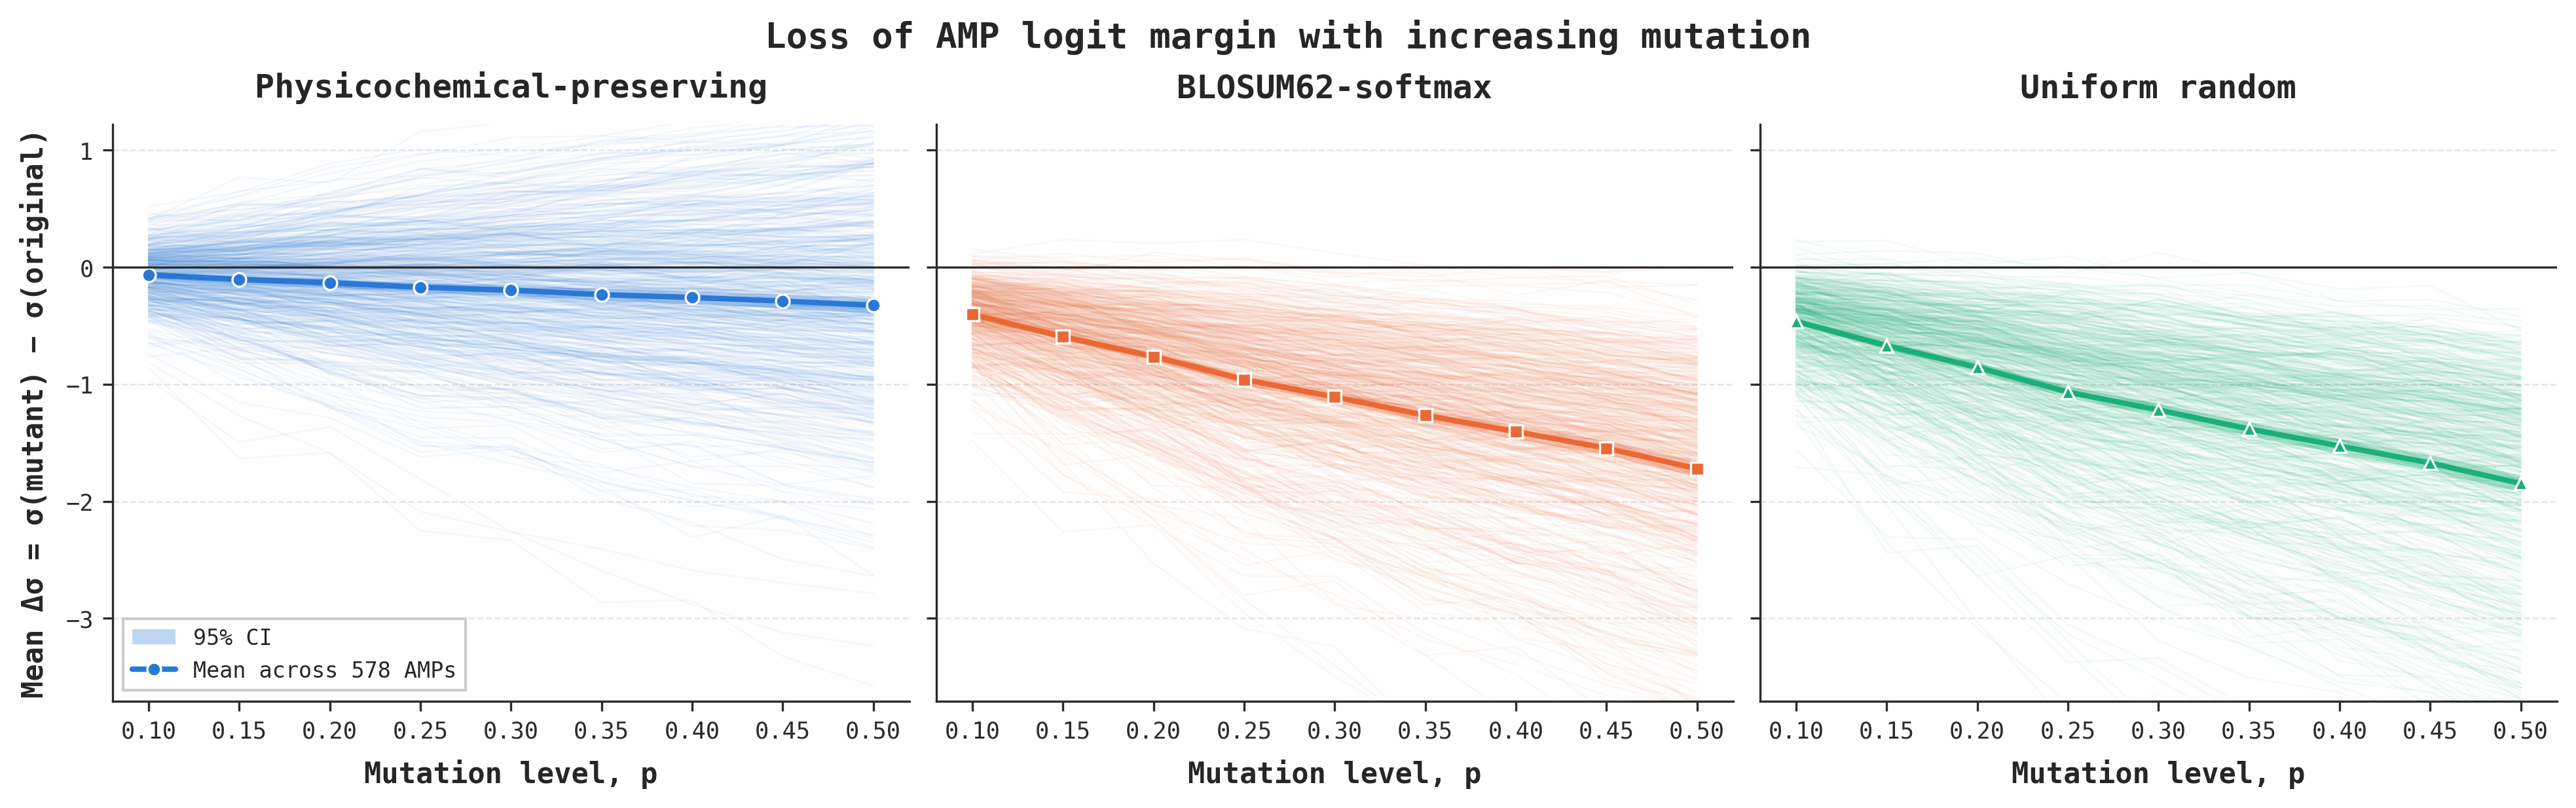

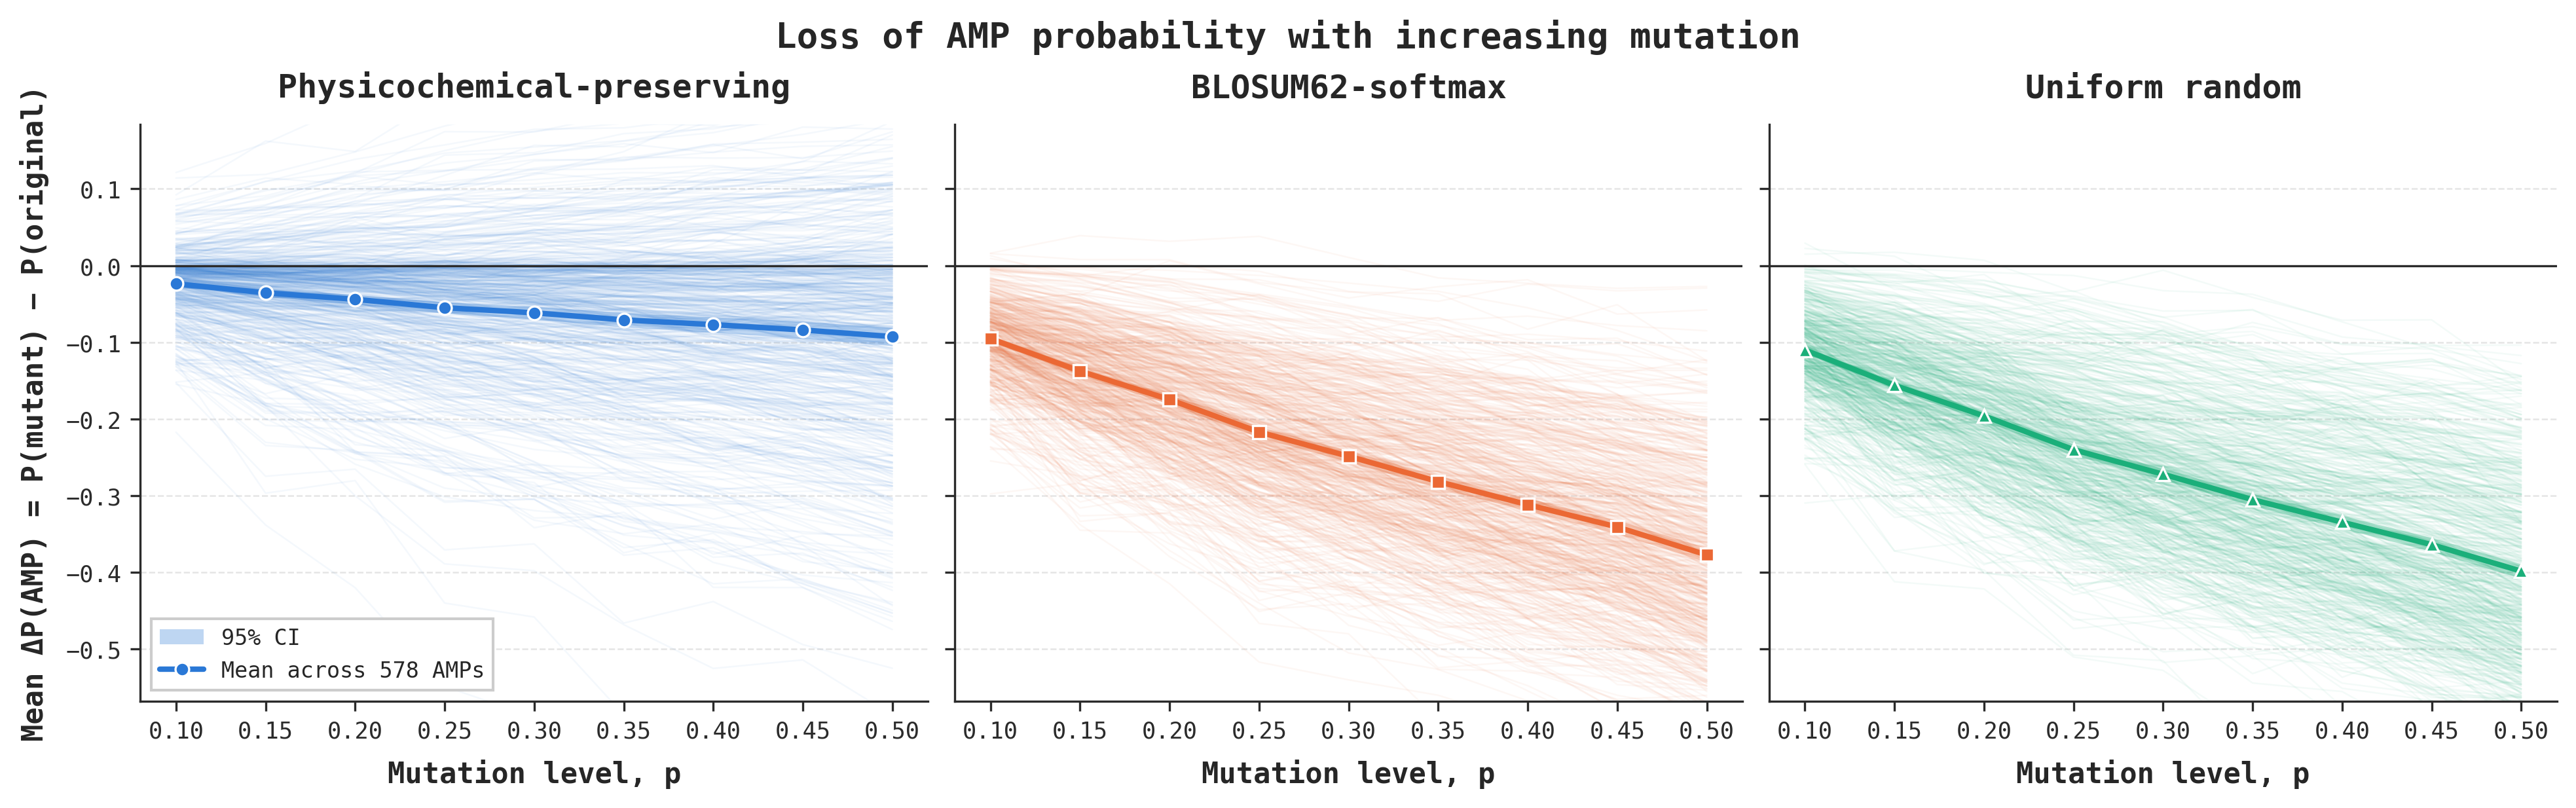

In [3]:
def mean_ci(frame: pd.DataFrame, value: str) -> pd.DataFrame:
    """Per-p mean across parents with a normal-approximation 95% CI."""
    stats = frame.groupby("p")[value].agg(["mean", "std", "count"])
    half_width = 1.96 * stats["std"] / np.sqrt(stats["count"])
    stats["low"] = stats["mean"] - half_width
    stats["high"] = stats["mean"] + half_width
    return stats.reset_index()


def plot_delta_vs_p(frame: pd.DataFrame, value: str, y_label: str, title: str) -> None:
    figure, axes = plt.subplots(1, len(SCHEME_ORDER), figsize=(13.0, 4.0), dpi=300,
                                sharey=True, layout="constrained")
    for axis, scheme in zip(axes, SCHEME_ORDER):
        subset = frame[frame["scheme"] == scheme]
        color = SCHEME_COLOR[scheme]

        spaghetti = subset.pivot(index="p", columns="parent_id", values=value)
        axis.plot(spaghetti.index, spaghetti.to_numpy(), color=color, alpha=0.05, linewidth=0.6)

        stats = mean_ci(subset, value)
        axis.fill_between(stats["p"], stats["low"], stats["high"], color=color, alpha=0.3,
                          linewidth=0, label="95% CI")
        axis.plot(stats["p"], stats["mean"], color=color, linewidth=2.0,
                  marker=SCHEME_MARKER[scheme], markersize=5, markeredgecolor="white",
                  markeredgewidth=0.8, label=f"Mean across {subset['parent_id'].nunique():,} AMPs")

        axis.axhline(0.0, color=SPINE_COLOR, linewidth=0.8)
        axis.set_title(SCHEME_LABEL[scheme], fontsize=TITLE_SIZE, fontweight="bold", pad=10)
        axis.set_xlabel("Mutation level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
        axis.set_xticks(P_LEVELS)
        style_axes(axis)

    # Clip to the bulk so the means stay legible; a few peptides run far past this.
    low, high = np.nanpercentile(frame[value], [0.5, 99.5])
    axes[0].set_ylim(low, max(high, 0.0) + 0.05 * (high - low))
    axes[0].set_ylabel(y_label, fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    axes[0].legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
    figure.suptitle(title, fontsize=TITLE_SIZE + 1, fontweight="bold")
    plt.show()


plot_delta_vs_p(
    amp_curves,
    "delta_sigma",
    "Mean Δσ = σ(mutant) − σ(original)",
    "Loss of AMP logit margin with increasing mutation",
)
plot_delta_vs_p(
    amp_curves,
    "delta_prob_AMP",
    "Mean ΔP(AMP) = P(mutant) − P(original)",
    "Loss of AMP probability with increasing mutation",
)

## Figure 5 — retention versus p, scheme comparison

`retention` is the fraction of the 500 replicates in a cell still called AMP, so this is a
survival curve against mutation dose. The claim the figure tests: conservative substitutions
should degrade the call more slowly than uniform random ones.

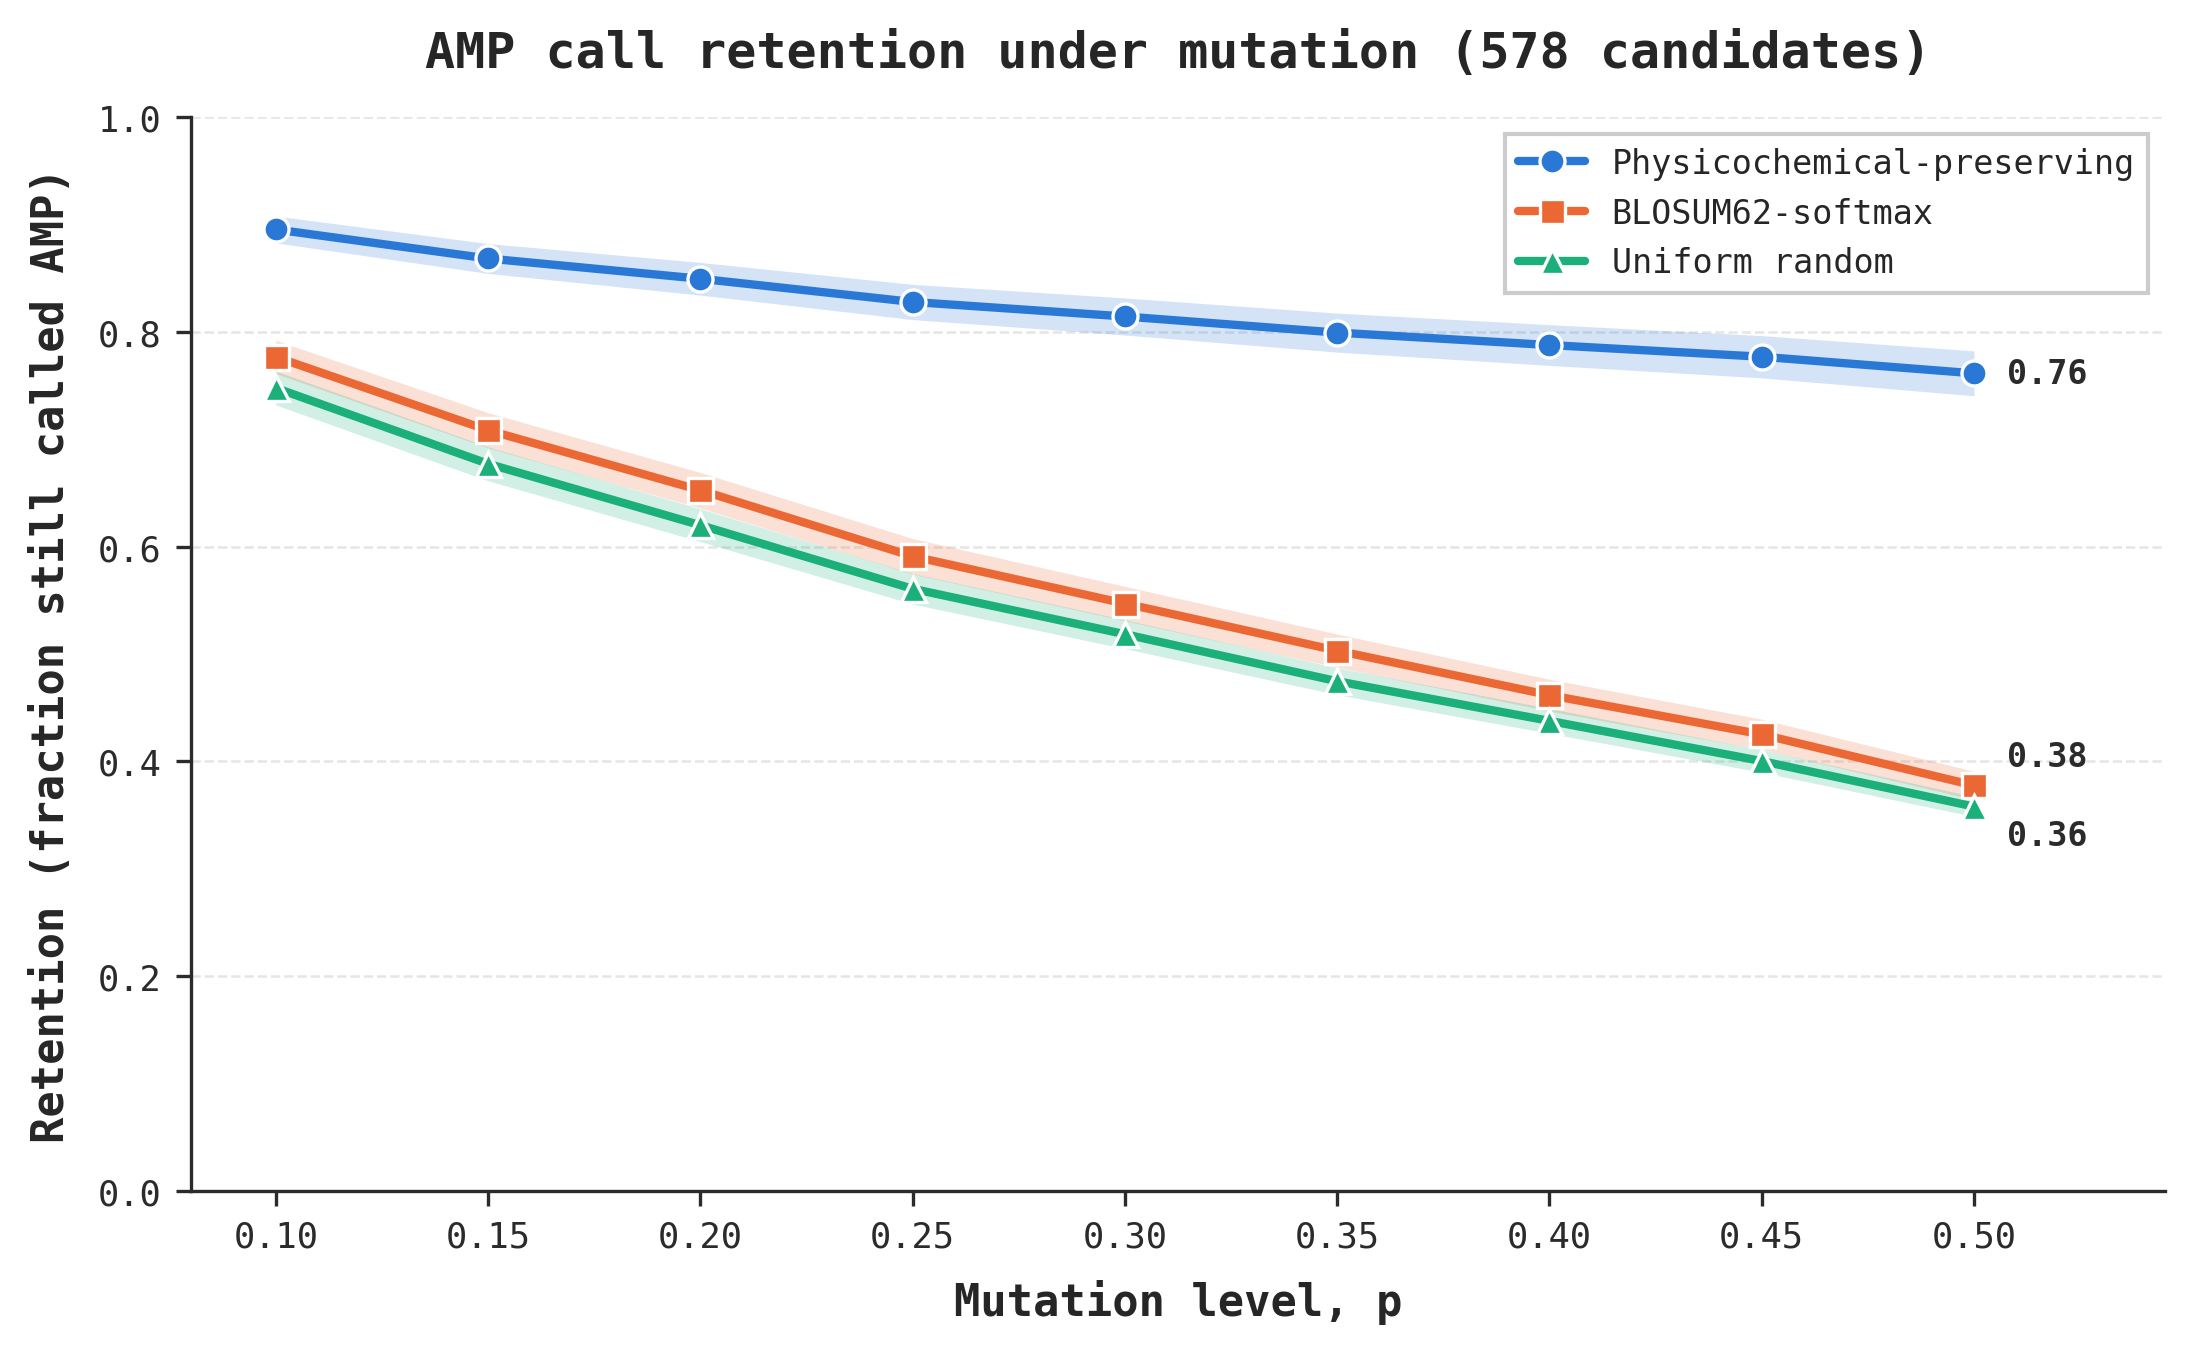

In [4]:
LABEL_OFFSET = {"physicochemical": 0.0, "blosum62": 7.0, "uniform": -7.0}

figure, axis = plt.subplots(figsize=(7.2, 4.4), dpi=300, layout="constrained")
for scheme in SCHEME_ORDER:
    stats = mean_ci(amp_curves[amp_curves["scheme"] == scheme], "retention")
    color = SCHEME_COLOR[scheme]
    axis.fill_between(stats["p"], stats["low"], stats["high"], color=color, alpha=0.2, linewidth=0)
    axis.plot(stats["p"], stats["mean"], color=color, linewidth=2.0,
              marker=SCHEME_MARKER[scheme], markersize=6, markeredgecolor="white",
              markeredgewidth=0.8, label=SCHEME_LABEL[scheme])
    axis.annotate(f"{stats['mean'].iloc[-1]:.2f}", (stats["p"].iloc[-1], stats["mean"].iloc[-1]),
                  textcoords="offset points", xytext=(8, LABEL_OFFSET[scheme]),
                  color=SPINE_COLOR, fontsize=8, fontweight="bold", va="center")

axis.set_xlabel("Mutation level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_ylabel("Retention (fraction still called AMP)", fontsize=LABEL_SIZE,
                fontweight="bold", labelpad=6)
axis.set_xticks(P_LEVELS)
axis.set_xlim(right=0.545)
axis.set_ylim(0, 1)
axis.legend(loc="upper right", fontsize=8, frameon=True, fancybox=False, framealpha=1)
axis.set_title(f"AMP call retention under mutation ({amp_curves['parent_id'].nunique():,} candidates)",
               fontsize=TITLE_SIZE, fontweight="bold", pad=12)
style_axes(axis)
plt.show()

## Caveat — nominal `p` is not a distinct dose at short lengths

`k = floor(p·L + 0.5)`, so several nominal `p` levels collapse onto the same substitution
count for short peptides. Those cells re-measure a dose already measured, which shows up as a
stair-step in the curves above and makes `retention_auc` weight doses unevenly in a way that
varies with length. The table below quantifies it for the loaded run.

In [5]:
redundancy = curves.copy()
redundancy["duplicate_k"] = redundancy.duplicated(["parent_id", "scheme", "k_requested"])
by_length = redundancy.groupby("length").agg(
    cells=("duplicate_k", "size"),
    redundant=("duplicate_k", "sum"),
)
by_length["fraction"] = (by_length["redundant"] / by_length["cells"]).round(3)

overall = redundancy["duplicate_k"].mean()
print(f"redundant cells: {redundancy['duplicate_k'].sum():,} / {len(redundancy):,} ({overall:.1%})")
print(f"variants spent re-measuring a known dose: {redundancy.loc[redundancy['duplicate_k'], 'n_variants'].sum():,}")
by_length.head(12)

redundant cells: 2,982 / 28,998 (10.3%)
variants spent re-measuring a known dose: 1,491,000


,cells,redundant,fraction
length,,,
8,81,45,0.556
9,162,72,0.444
10,378,168,0.444
11,945,315,0.333
12,1350,450,0.333
13,1323,294,0.222
14,1836,408,0.222
15,1728,384,0.222
16,1809,402,0.222
